# Notebook 1 — Results Comparison

**Purpose:** Paper-ready comparison of final Best Result scores across all 7 experiments.

**Input:** One `stdout.log` file per experiment (produced by `train.py` / `test.py` with the `_Tee` redirect).

**Outputs:**
- Summary table (harmonic + arithmetic subset-mean F-measure, precision, recall)
- Grouped bar: harmonic subset-mean F-measure per experiment
- Grouped bar: arithmetic subset-mean F-measure per experiment
- Grouped bar: precision / recall / F-measure for each experiment
- Paired bar: no-postproc vs best-postproc F-measure per experiment
- LaTeX table export

## 0 — Configuration

Edit `EXPERIMENT_LOGS` to point to your log files.

In [ ]:
import sys
from pathlib import Path

# ── Add notebooks/ to path so parse_logs can be imported ──────────────────
sys.path.insert(0, str(Path(".").resolve()))
import parse_logs as pl

# ── Experiment log paths ───────────────────────────────────────────────────
# Fill in the actual paths to each run's stdout.log.
# Leave the value as None to skip an experiment.
EXPERIMENT_LOGS = {
    "Baseline":            "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/baseline_seed1234/2026-09-17_09-08-46/stdout.log",  # e.g. "../logs/experiments/runs/baseline/2026-.../stdout.log"
    "CIFE":                "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/cife_seed1234/2026-09-17_22-11-22/stdout.log",
    "Slot Uniform":        "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/slot_uniform_seed1234/2026-09-18_12-05-18/stdout.log",
    "Phase 1 (Random)":    "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/phase1_random_seed1234/2026-09-18_05-15-56/stdout.log",
    "Phase 2 (Energy)":    "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/phase2_energy_seed1234/2026-09-18_16-56-51/stdout.log",
    "Phase 3 (Activation)": "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/phase3_seed1234_output.log",
    "AFRI (Direct)": "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/afri_direct_seed1234/2026-09-19_14-20-53/stdout.log",
    "AFRI (Inverse)": "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/afri_inverse_seed1234/2026-09-19_20-45-13/stdout.log",
}

# Filter out None entries for parsing
logs_to_parse = {k: v for k, v in EXPERIMENT_LOGS.items() if v is not None}
print(f"Parsing {len(logs_to_parse)} experiment(s)...")

Parsing 8 experiment(s)...


## 1 — Load & Parse Logs

In [12]:
experiments = pl.load_experiments(logs_to_parse)

  ✓ Baseline                        fmeasure=16.615
  ✓ CIFE                            fmeasure=15.296
  ✓ Slot Uniform                    fmeasure=15.392
  ✓ Phase 1 (Random)                fmeasure=15.618
  ✓ Phase 2 (Energy)                fmeasure=15.434
  ✓ Phase 3 (Activation)            fmeasure=15.304
  ✓ AFRI (Direct)                   fmeasure=15.502
  ✓ AFRI (Inverse)                  fmeasure=15.613


## 2 — Summary Table

In [13]:
import pandas as pd

df_final = pl.final_results_df(experiments)

# Round for display
display_cols = ["fmeasure", "fmeasureavg", "precision", "recall", "precisionavg", "recallavg"]
display_cols = [c for c in display_cols if c in df_final.columns]

# Rename for readability
rename = {
    "fmeasure":      "F-measure (harmonic)",
    "fmeasureavg":  "F-measure (arithmetic)",
    "precision":     "Precision (harmonic)",
    "recall":        "Recall (harmonic)",
    "precisionavg": "Precision (arithmetic)",
    "recallavg":    "Recall (arithmetic)",
}
df_display = df_final[display_cols].rename(columns=rename).round(4)

print("=== Final Best Result — Summary ===")
display(df_display)

=== Final Best Result — Summary ===


,F-measure (harmonic),F-measure (arithmetic),Precision (harmonic),Recall (harmonic),Precision (arithmetic),Recall (arithmetic)
experiment,,,,,,
Baseline,16.615,28.489,0.1210,0.2648,0.2915,0.5337
CIFE,15.296,29.524,0.1239,0.1998,0.2847,0.5349
Slot Uniform,15.392,27.540,0.1061,0.2799,0.2542,0.5413
Phase 1 (Random),15.618,27.646,0.1080,0.2820,0.2580,0.5431
Phase 2 (Energy),15.434,27.475,0.1054,0.2883,0.2553,0.5443
Phase 3 (Activation),15.304,27.743,0.1148,0.2295,0.2633,0.5247
AFRI (Direct),15.502,27.870,0.1099,0.2632,0.2573,0.5403
AFRI (Inverse),15.613,27.283,0.1074,0.2858,0.2543,0.5397


## 3 — LaTeX Table Export

In [14]:
# Multiply precision/recall (0-1) by 100 to match fmeasure scale
df_latex = df_display.copy()
for col in ["Precision (harmonic)", "Recall (harmonic)", "Precision (arithmetic)", "Recall (arithmetic)"]:
    if col in df_latex.columns:
        df_latex[col] = (df_latex[col] * 100).round(2)

latex_str = df_latex.to_latex(
    float_format="%.2f",
    caption="Comparison of 7 experiment configurations on DCASE 2024 Task 5 validation set. "
            "F-measure values are on a 0–100 scale.",
    label="tab:results_comparison",
    bold_rows=True,
)
print(latex_str)

\begin{table}
\centering
\caption{Comparison of 7 experiment configurations on DCASE 2024 Task 5 validation set. F-measure values are on a 0–100 scale.}
\label{tab:results_comparison}
\begin{tabular}{lrrrrrr}
\toprule
{} &  F-measure (harmonic) &  F-measure (arithmetic) &  Precision (harmonic) &  Recall (harmonic) &  Precision (arithmetic) &  Recall (arithmetic) \\
\textbf{experiment          } &                       &                         &                       &                    &                         &                      \\
\midrule
\textbf{Baseline            } &                 16.61 &                   28.49 &                 12.10 &              26.48 &                   29.15 &                53.37 \\
\textbf{CIFE                } &                 15.30 &                   29.52 &                 12.39 &              19.98 &                   28.47 &                53.49 \\
\textbf{Slot Uniform        } &                 15.39 &                   27.54 &           

## 4 — Bar Charts

In [15]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

# ── Shared style ───────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.4,
    "font.size": 11,
})

COLORS = plt.cm.tab10.colors

experiments_list = list(df_display.index)
x = np.arange(len(experiments_list))
bar_width = 0.55

### 4a — F-measure (Harmonic Subset Mean)

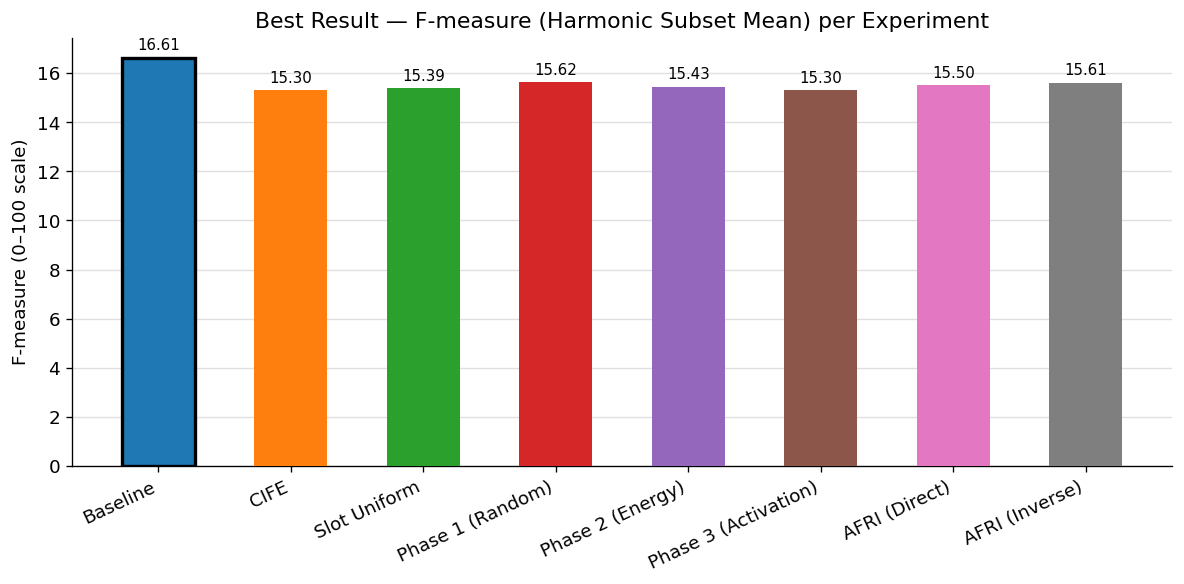

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))

vals = df_display["F-measure (harmonic)"].values
bars = ax.bar(x, vals, width=bar_width, color=COLORS[:len(x)], zorder=3)

# Annotate bars
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
            f"{v:.2f}", ha="center", va="bottom", fontsize=9)

# Highlight best
best_idx = int(np.argmax(vals))
bars[best_idx].set_edgecolor("black")
bars[best_idx].set_linewidth(2)

ax.set_xticks(x)
ax.set_xticklabels(experiments_list, rotation=25, ha="right")
ax.set_ylabel("F-measure (0–100 scale)")
ax.set_title("Best Result — F-measure (Harmonic Subset Mean) per Experiment")
plt.tight_layout()
plt.savefig("fig_fmeasure_harmonic.pdf", bbox_inches="tight")
plt.show()

### 4b — F-measure (Arithmetic Subset Mean)

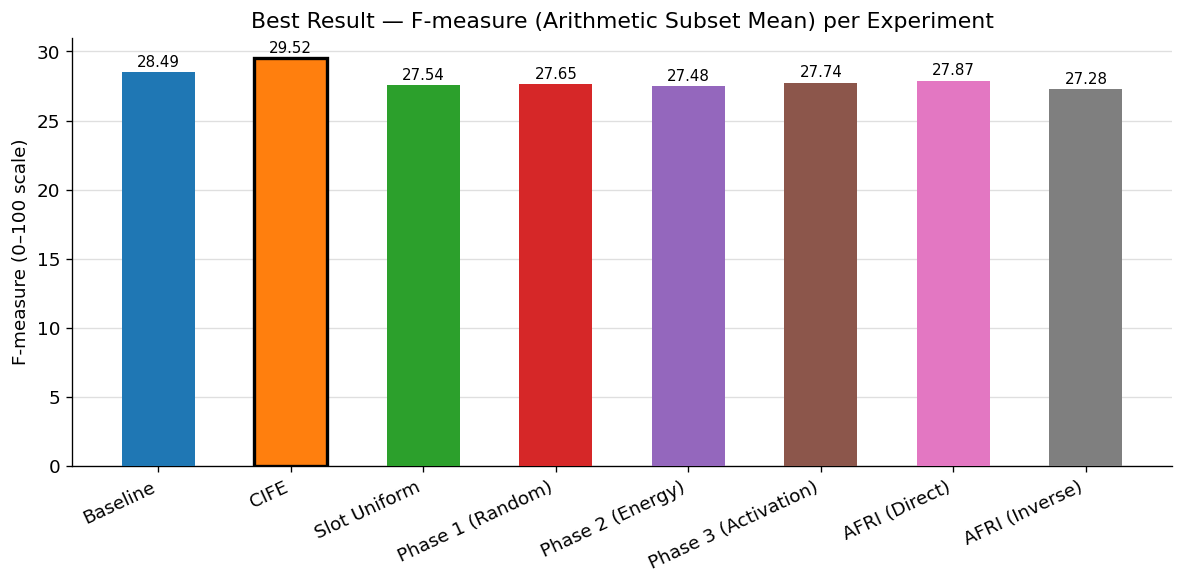

In [17]:
if "F-measure (arithmetic)" in df_display.columns:
    fig, ax = plt.subplots(figsize=(10, 5))
    vals = df_display["F-measure (arithmetic)"].values
    bars = ax.bar(x, vals, width=bar_width, color=COLORS[:len(x)], zorder=3)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
                f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    best_idx = int(np.argmax(vals))
    bars[best_idx].set_edgecolor("black")
    bars[best_idx].set_linewidth(2)
    ax.set_xticks(x)
    ax.set_xticklabels(experiments_list, rotation=25, ha="right")
    ax.set_ylabel("F-measure (0–100 scale)")
    ax.set_title("Best Result — F-measure (Arithmetic Subset Mean) per Experiment")
    plt.tight_layout()
    plt.savefig("fig_fmeasure_arithmetic.pdf", bbox_inches="tight")
    plt.show()
else:
    print("Arithmetic subset-mean F-measure not available in parsed results.")

### 4c — Precision / Recall / F-measure grouped per experiment

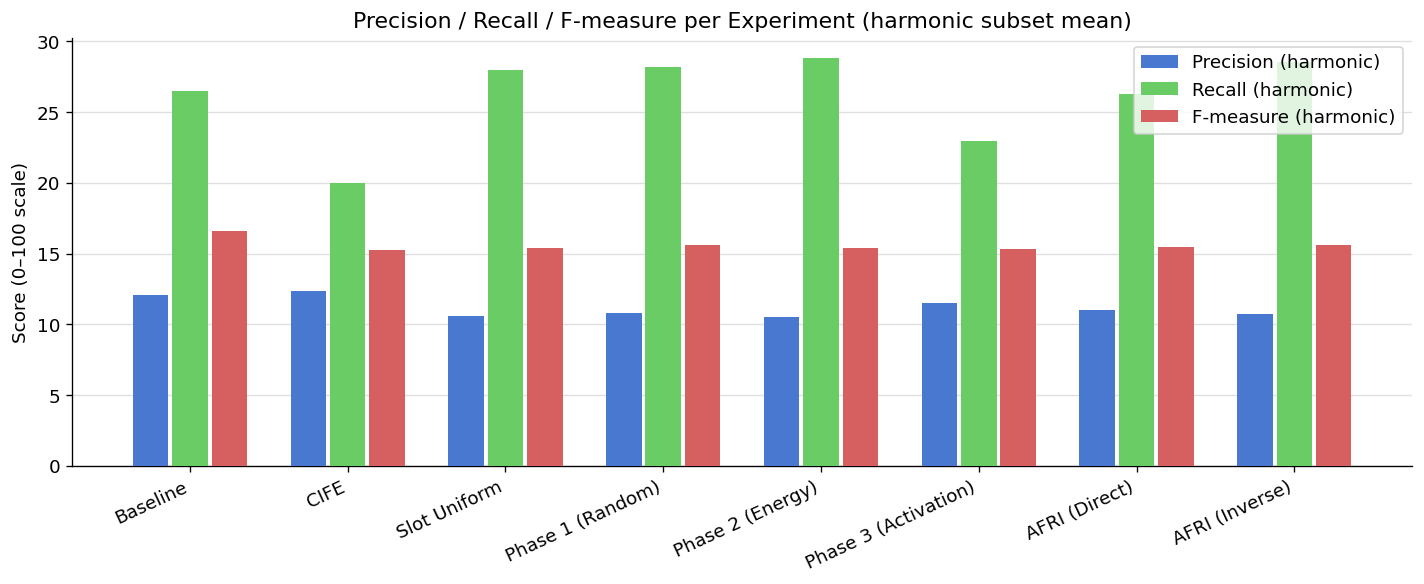

In [18]:
fig, ax = plt.subplots(figsize=(12, 5))

n_exp = len(experiments_list)
group_width = 0.75
metric_cols = [c for c in ["Precision (harmonic)", "Recall (harmonic)", "F-measure (harmonic)"] if c in df_display.columns]
n_metrics = len(metric_cols)
w = group_width / n_metrics
metric_colors = ["#4878CF", "#6ACC65", "#D65F5F"]

for mi, (col, color) in enumerate(zip(metric_cols, metric_colors)):
    offset = (mi - n_metrics / 2 + 0.5) * w
    vals = df_display[col].values
    # Precision and recall are 0-1; multiply by 100
    if "F-measure" not in col:
        vals = vals * 100
    bars = ax.bar(x + offset, vals, width=w * 0.9, color=color,
                  label=col, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(experiments_list, rotation=25, ha="right")
ax.set_ylabel("Score (0–100 scale)")
ax.set_title("Precision / Recall / F-measure per Experiment (harmonic subset mean)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("fig_prec_rec_f.pdf", bbox_inches="tight")
plt.show()

### 4d — No-postproc vs Best-postproc F-measure

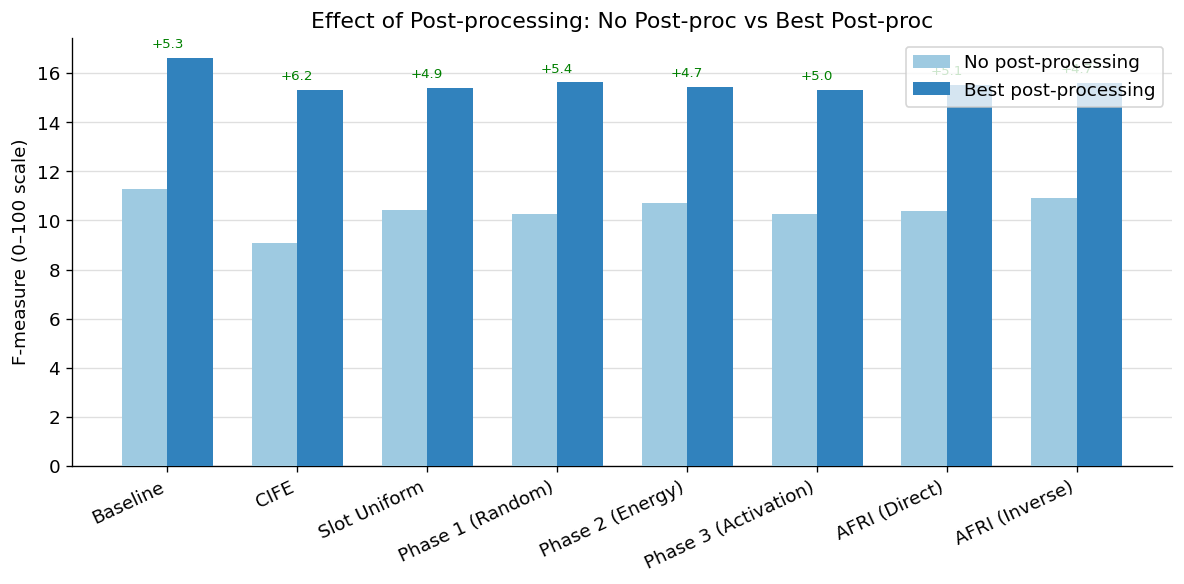

In [19]:
df_nopost = pl.no_postproc_df(experiments)

if not df_nopost.empty:
    # For each experiment take the no-postproc score at the winning detection threshold
    # (proxy: max no-postproc fmeasure across all k values)
    no_post_best = (
        df_nopost.groupby("experiment")["fmeasure"]
        .max()
        .reindex(experiments_list)
    )
    post_best = df_display["F-measure (harmonic)"].reindex(experiments_list)

    fig, ax = plt.subplots(figsize=(10, 5))
    w = 0.35
    bars_no  = ax.bar(x - w/2, no_post_best.values, width=w,
                      label="No post-processing", color="#9ECAE1", zorder=3)
    bars_yes = ax.bar(x + w/2, post_best.values,    width=w,
                      label="Best post-processing", color="#3182BD", zorder=3)

    # Annotate gain
    for i_b, (v_no, v_yes) in enumerate(zip(no_post_best.values, post_best.values)):
        if v_no is not None and v_yes is not None:
            gain = v_yes - v_no
            color = "green" if gain >= 0 else "red"
            ax.text(x[i_b], max(v_no, v_yes) + 0.3,
                    f"{gain:+.1f}", ha="center", va="bottom",
                    fontsize=8, color=color)

    ax.set_xticks(x)
    ax.set_xticklabels(experiments_list, rotation=25, ha="right")
    ax.set_ylabel("F-measure (0–100 scale)")
    ax.set_title("Effect of Post-processing: No Post-proc vs Best Post-proc")
    ax.legend()
    plt.tight_layout()
    plt.savefig("fig_postproc_gain.pdf", bbox_inches="tight")
    plt.show()
else:
    print("No-postproc data not available (check log parsing).")

## 5 — Harmonic vs Arithmetic Subset-Mean F-measure scatter

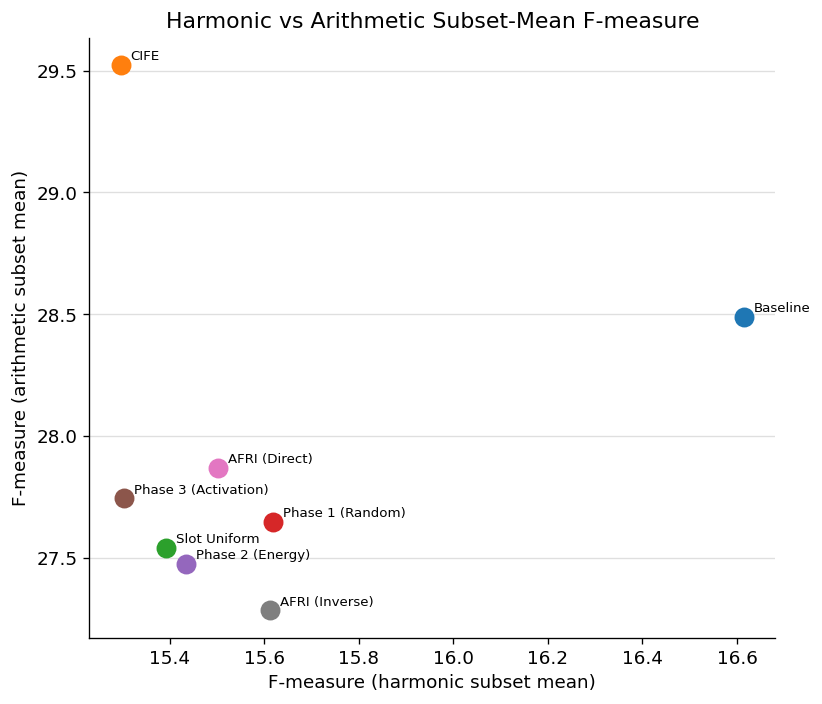

In [20]:
if "F-measure (arithmetic)" in df_display.columns:
    fig, ax = plt.subplots(figsize=(7, 6))
    f_harm = df_display["F-measure (harmonic)"].values
    f_arith = df_display["F-measure (arithmetic)"].values

    for i_e, (xv, yv, label) in enumerate(zip(f_harm, f_arith, experiments_list)):
        ax.scatter(xv, yv, s=120, color=COLORS[i_e], zorder=3)
        ax.annotate(label, (xv, yv), textcoords="offset points",
                    xytext=(6, 3), fontsize=8)

    ax.set_xlabel("F-measure (harmonic subset mean)")
    ax.set_ylabel("F-measure (arithmetic subset mean)")
    ax.set_title("Harmonic vs Arithmetic Subset-Mean F-measure")
    plt.tight_layout()
    plt.savefig("fig_harmonic_vs_arithmetic.pdf", bbox_inches="tight")
    plt.show()